In [ ]:
import sys, site, importlib

!pip install --user -q nucleus-cdk==0.6.0rc1
!pip install --user -q pyarrow

user_site = site.getusersitepackages()
if user_site not in sys.path:
    sys.path.insert(0, user_site)
importlib.invalidate_caches()

import importlib.metadata as md
assert md.version("nucleus-cdk") == "0.6.0rc1", f"got {md.version('nucleus-cdk')}"

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from cdk import logging
log = logging.setup_logging(logging.INFO)

# Import the cdk platereader module
from cdk.instruments import platereader as pr

INFO:cdk.logging:Logging initialized


In [ ]:
import sys
sys.path

['/content',
 '/env/python',
 '/usr/lib/python313.zip',
 '/usr/lib/python3.13',
 '/usr/lib/python3.13/lib-dynload',
 '',
 '/usr/local/lib/python3.13/dist-packages',
 '/usr/lib/python3/dist-packages',
 '/usr/local/lib/python3.13/dist-packages/IPython/extensions',
 '/root/.ipython']

In [ ]:
from cdk.analysis.cell import microscopy as m

## Load data

Will put a proper read parquet in the actual microscopy CDK code. Once that's done there's a load function that will also take a platemap (like the the platereader).

In [ ]:
data_Neg = pd.read_parquet(
    "https://data.nucleus.engineering/microscopy/2026-07-31_TetR-5hrs-E3-E4-post_bleach-v2-correct_2026-07-31_20-22-54.551591.parquet",
    storage_options={
        "User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                      "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"
    }
)

# data = data.merge(platemap, on="Well")
# data = data.sort_values(by=["Experiment", "Name", "Timepoint"])

In [ ]:
data_POS = pd.read_parquet(
    "https://data.nucleus.engineering/microscopy/2026-07-31_TetR-5hrs-E5-E8-post_bleach-v2-correct_2026-07-31_20-20-36.657110.parquet",
    storage_options={
        "User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                      "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"
    }
)

In [ ]:
data_EXP_OFF = pd.read_parquet(
    "https://data.nucleus.engineering/microscopy/2026-07-31_TetR-5hrs-E9-E10-post_bleach-v2-correct_2026-07-31_20-05-00.244751.parquet",
    storage_options={
        "User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                      "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"
    }
)

In [ ]:
data_EXP_ON = pd.read_parquet(
    "https://data.nucleus.engineering/microscopy/2026-07-31_TetR-5hrs-E11-E12-post_bleach-v2-correct_2026-07-31_20-03-27.638945.parquet",
    storage_options={
        "User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                      "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"
    }
)

In [ ]:

# Prepare data_Neg
df_neg = data_Neg.copy()
df_neg['source_group'] = 'NEG'

# Prepare data_POS
df_pos = data_POS[data_POS['Well'].isin(['E5'])].copy()
df_pos['source_group'] = 'POS'

# Prepare data_EXP_OFF, filtering for wells E9 and E10
df_exp_off = data_EXP_OFF[data_EXP_OFF['Well'].isin(['E9', 'E10'])].copy()
df_exp_off['source_group'] = 'EXP_OFF'

# Prepare data_EXP_ON
df_exp_on = data_EXP_ON.copy()
df_exp_on['source_group'] = 'EXP_ON'

# Combine all dataframes into GFP_expression_data
GFP_expression_data = pd.concat([df_neg, df_pos, df_exp_off, df_exp_on], ignore_index=True)

GFP_expression_data = GFP_expression_data[GFP_expression_data['Diameter (Equivalent) (um)'] > 5]

In [ ]:
GFP_expression_data.head()

,Label,Area (um^2),Diameter (Equivalent) (um),Diameter (Feret) (um),Length Major (um),Length Minor (um),Perimeter (um),Intensity Mean (GFP),Intensity Mean (Alexa Fluor 647),Intensity Max (GFP),...,Volume (um^3),Circularity,Intensity Sum (GFP),Intensity Norm (GFP),Intensity Sum (Alexa Fluor 647),Intensity Norm (Alexa Fluor 647),Timepoint,Dataset,Well,source_group
0,1,59.214726,8.683002,10.846807,10.576248,7.147467,28.975060,570.378277,444.647940,614.0,...,342.774406,0.886321,304582,1.664005,237442,1.297203,0,/data/microscopy/2026-07-31_TetR-5hrs-E3-E4-po...,E3,NEG
1,2,20.514465,5.110756,5.582097,5.164094,5.065237,16.192930,659.789189,518.978378,693.0,...,69.896285,0.983149,122061,9.439546,96011,7.424978,0,/data/microscopy/2026-07-31_TetR-5hrs-E3-E4-po...,E3,NEG
5,6,75.182742,9.783948,10.907974,10.619717,9.029671,32.271592,654.871681,549.097345,709.0,...,490.389363,0.907167,444003,1.335412,372288,1.119717,0,/data/microscopy/2026-07-31_TetR-5hrs-E3-E4-po...,E3,NEG
72,73,51.341607,8.085182,9.377365,9.263610,7.203245,26.977060,657.356371,551.311015,711.0,...,276.737483,0.886523,304356,2.375379,255257,1.992180,0,/data/microscopy/2026-07-31_TetR-5hrs-E3-E4-po...,E3,NEG
220,221,74.517408,9.740560,11.380613,10.951417,8.716702,32.385860,663.029762,603.166667,776.0,...,483.894193,0.892805,445556,1.370196,405328,1.246485,0,/data/microscopy/2026-07-31_TetR-5hrs-E3-E4-po...,E3,NEG


## Summary Plots

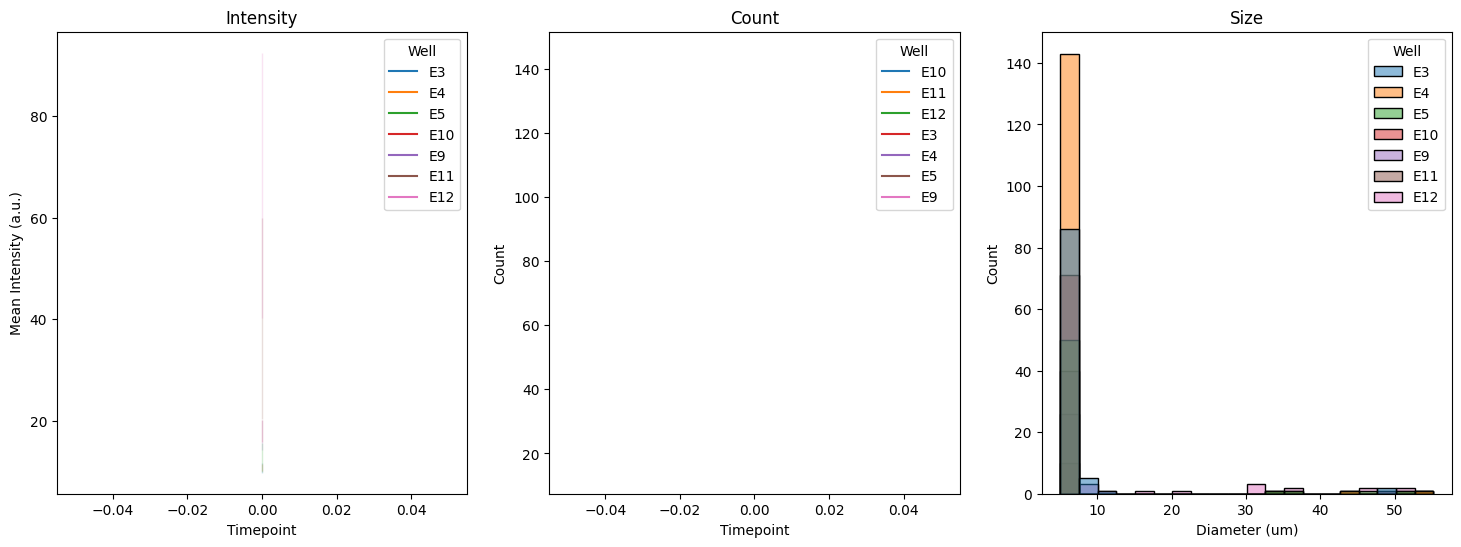

In [ ]:
m.plot_summary(GFP_expression_data )

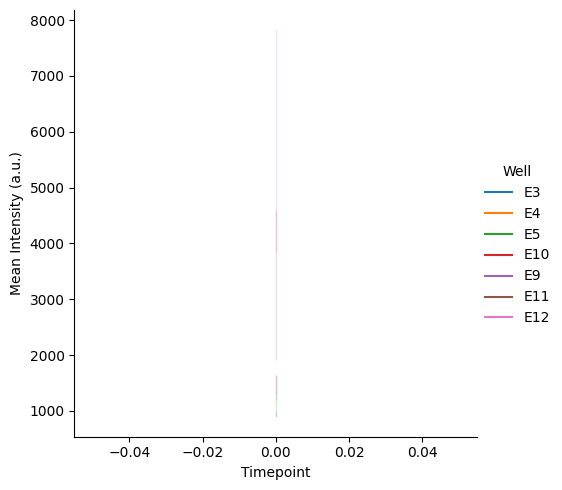

In [ ]:
m.plot_intensity(GFP_expression_data )

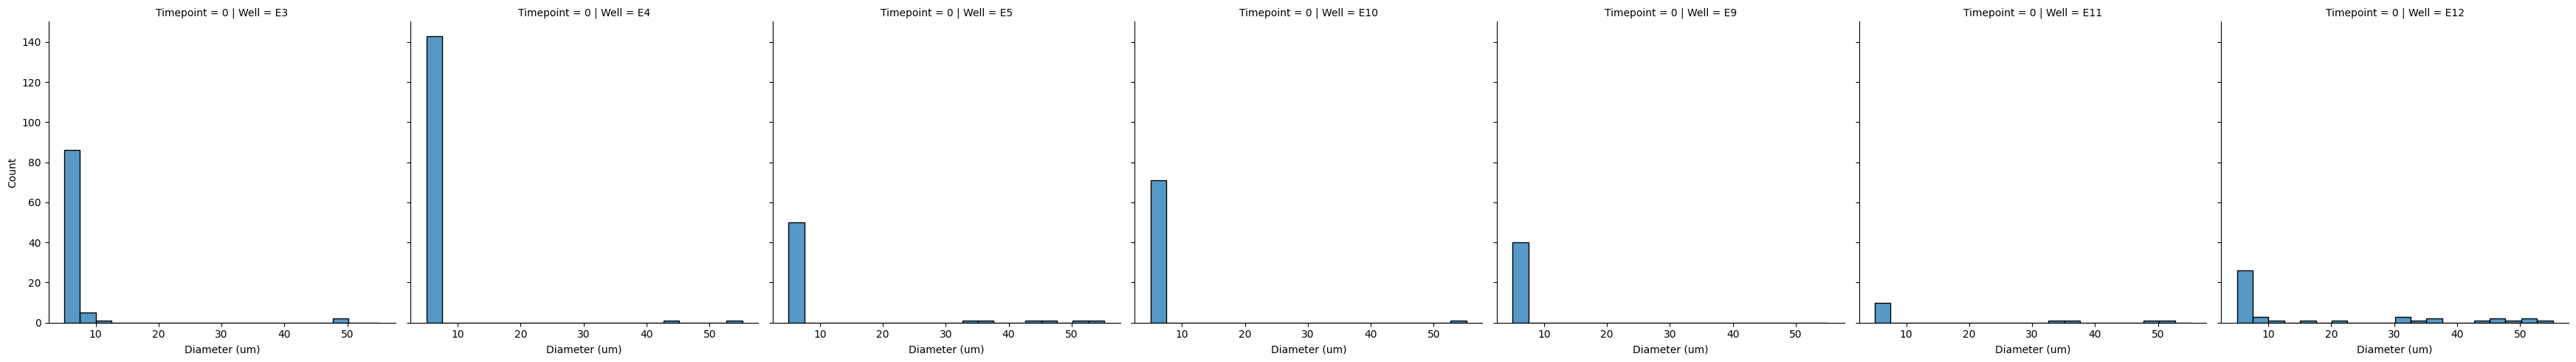

In [ ]:
m.plot_size(GFP_expression_data )

## Fogplots

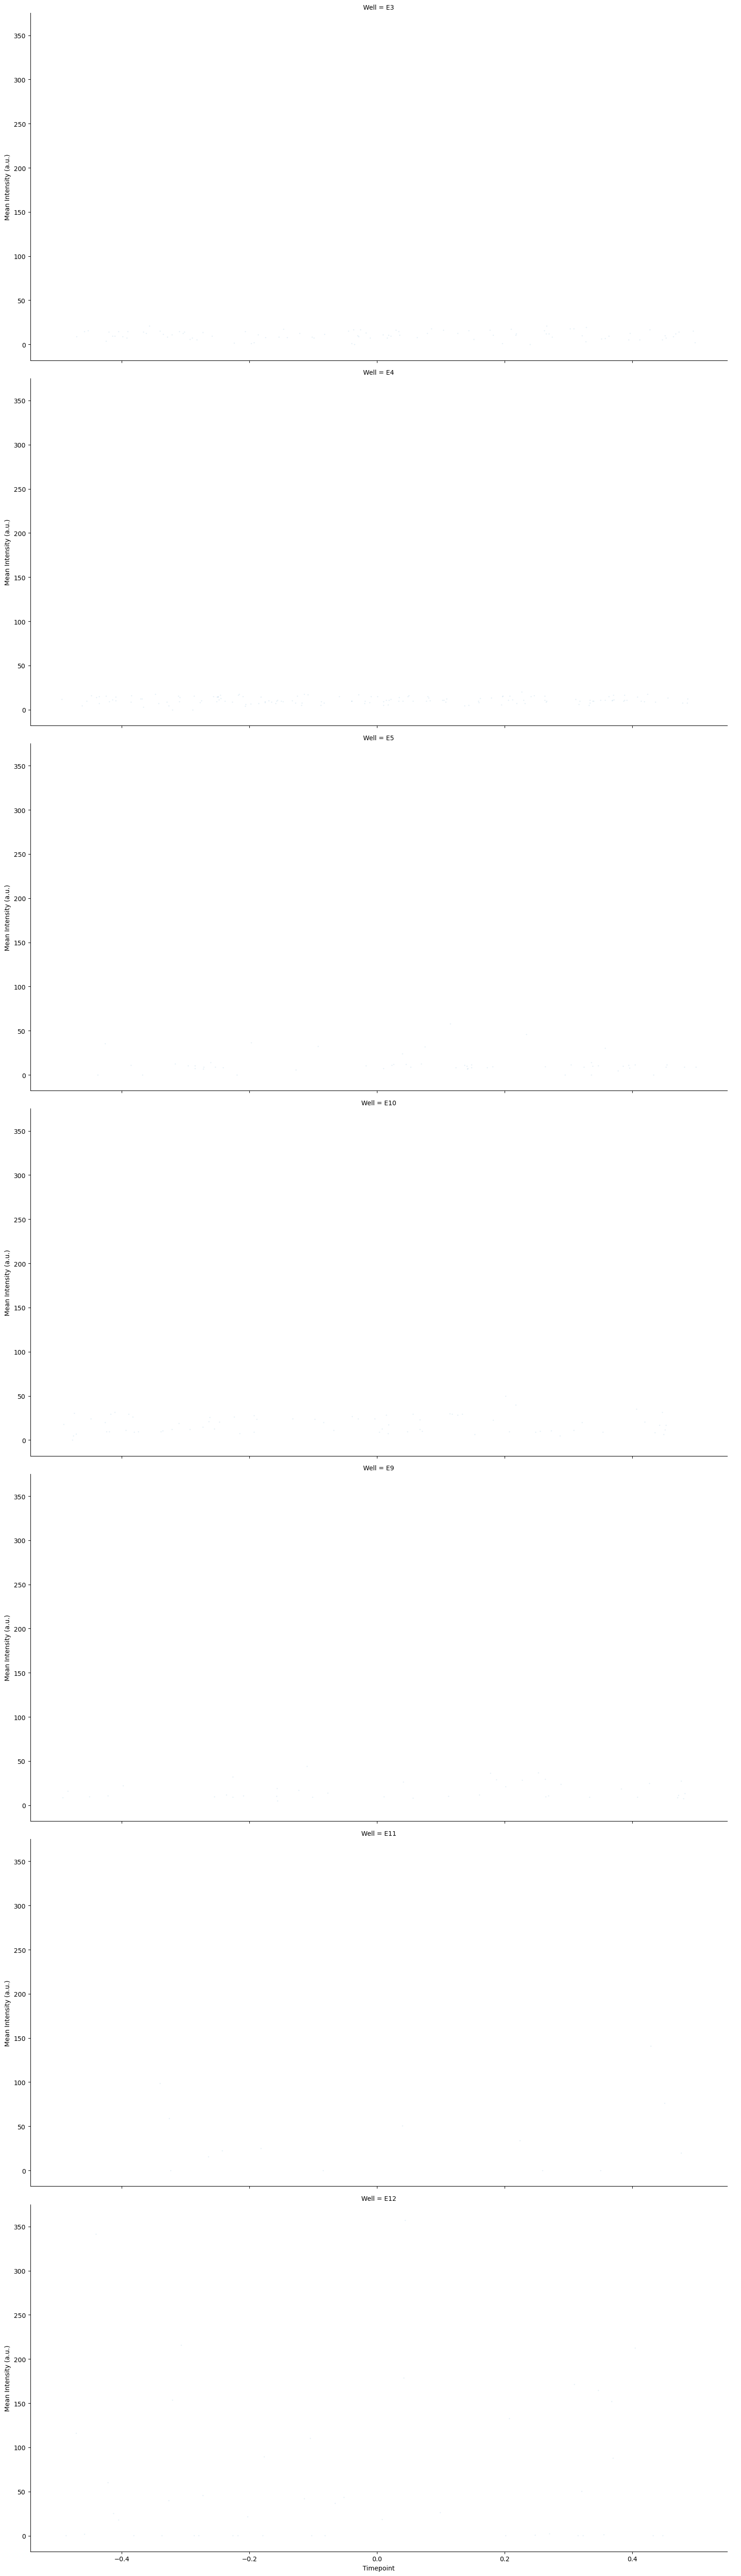

In [ ]:
m.plot_fogplot(GFP_expression_data )

##Plotting

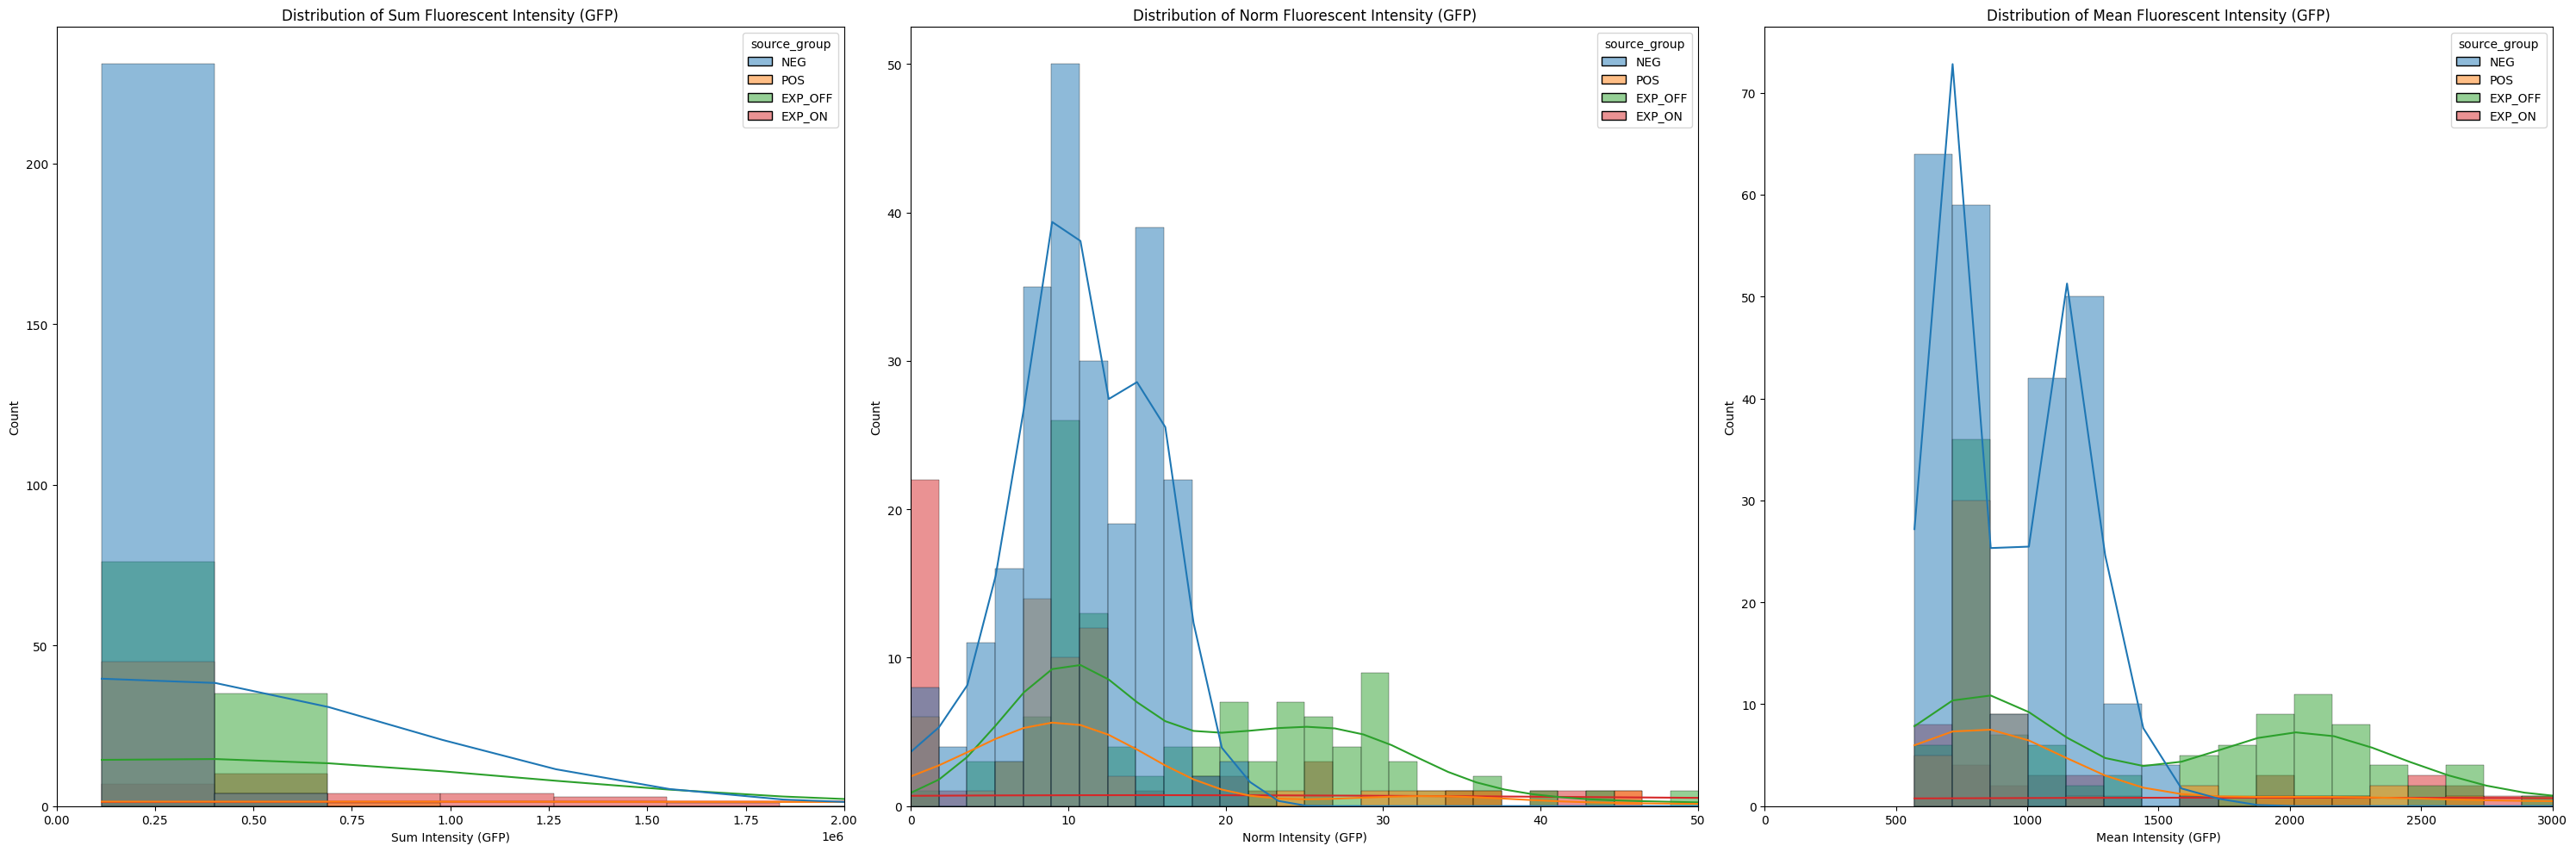

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(30, 10))

sns.histplot(data=GFP_expression_data, x='Intensity Sum (GFP)', hue='source_group', kde=True, bins=200, ax=axes[0])
axes[0].set_title('Distribution of Sum Fluorescent Intensity (GFP)')
axes[0].set_xlabel('Sum Intensity (GFP)')
axes[0].set_ylabel('Count')
x_max = 2e6
axes[0].set_xlim(0, x_max)

sns.histplot(data=GFP_expression_data, x='Intensity Norm (GFP)', hue='source_group', kde=True, bins=200, ax=axes[1])
axes[1].set_title('Distribution of Norm Fluorescent Intensity (GFP)')
axes[1].set_xlabel('Norm Intensity (GFP)')
axes[1].set_ylabel('Count')
x_max = 50
axes[1].set_xlim(0, x_max)

sns.histplot(data=GFP_expression_data, x='Intensity Mean (GFP)', hue='source_group', kde=True, bins=200, ax=axes[2])
axes[2].set_title('Distribution of Mean Fluorescent Intensity (GFP)')
axes[2].set_xlabel('Mean Intensity (GFP)')
axes[2].set_ylabel('Count')
x_max = 3e3
axes[2].set_xlim(0, x_max)

plt.tight_layout()
plt.show()

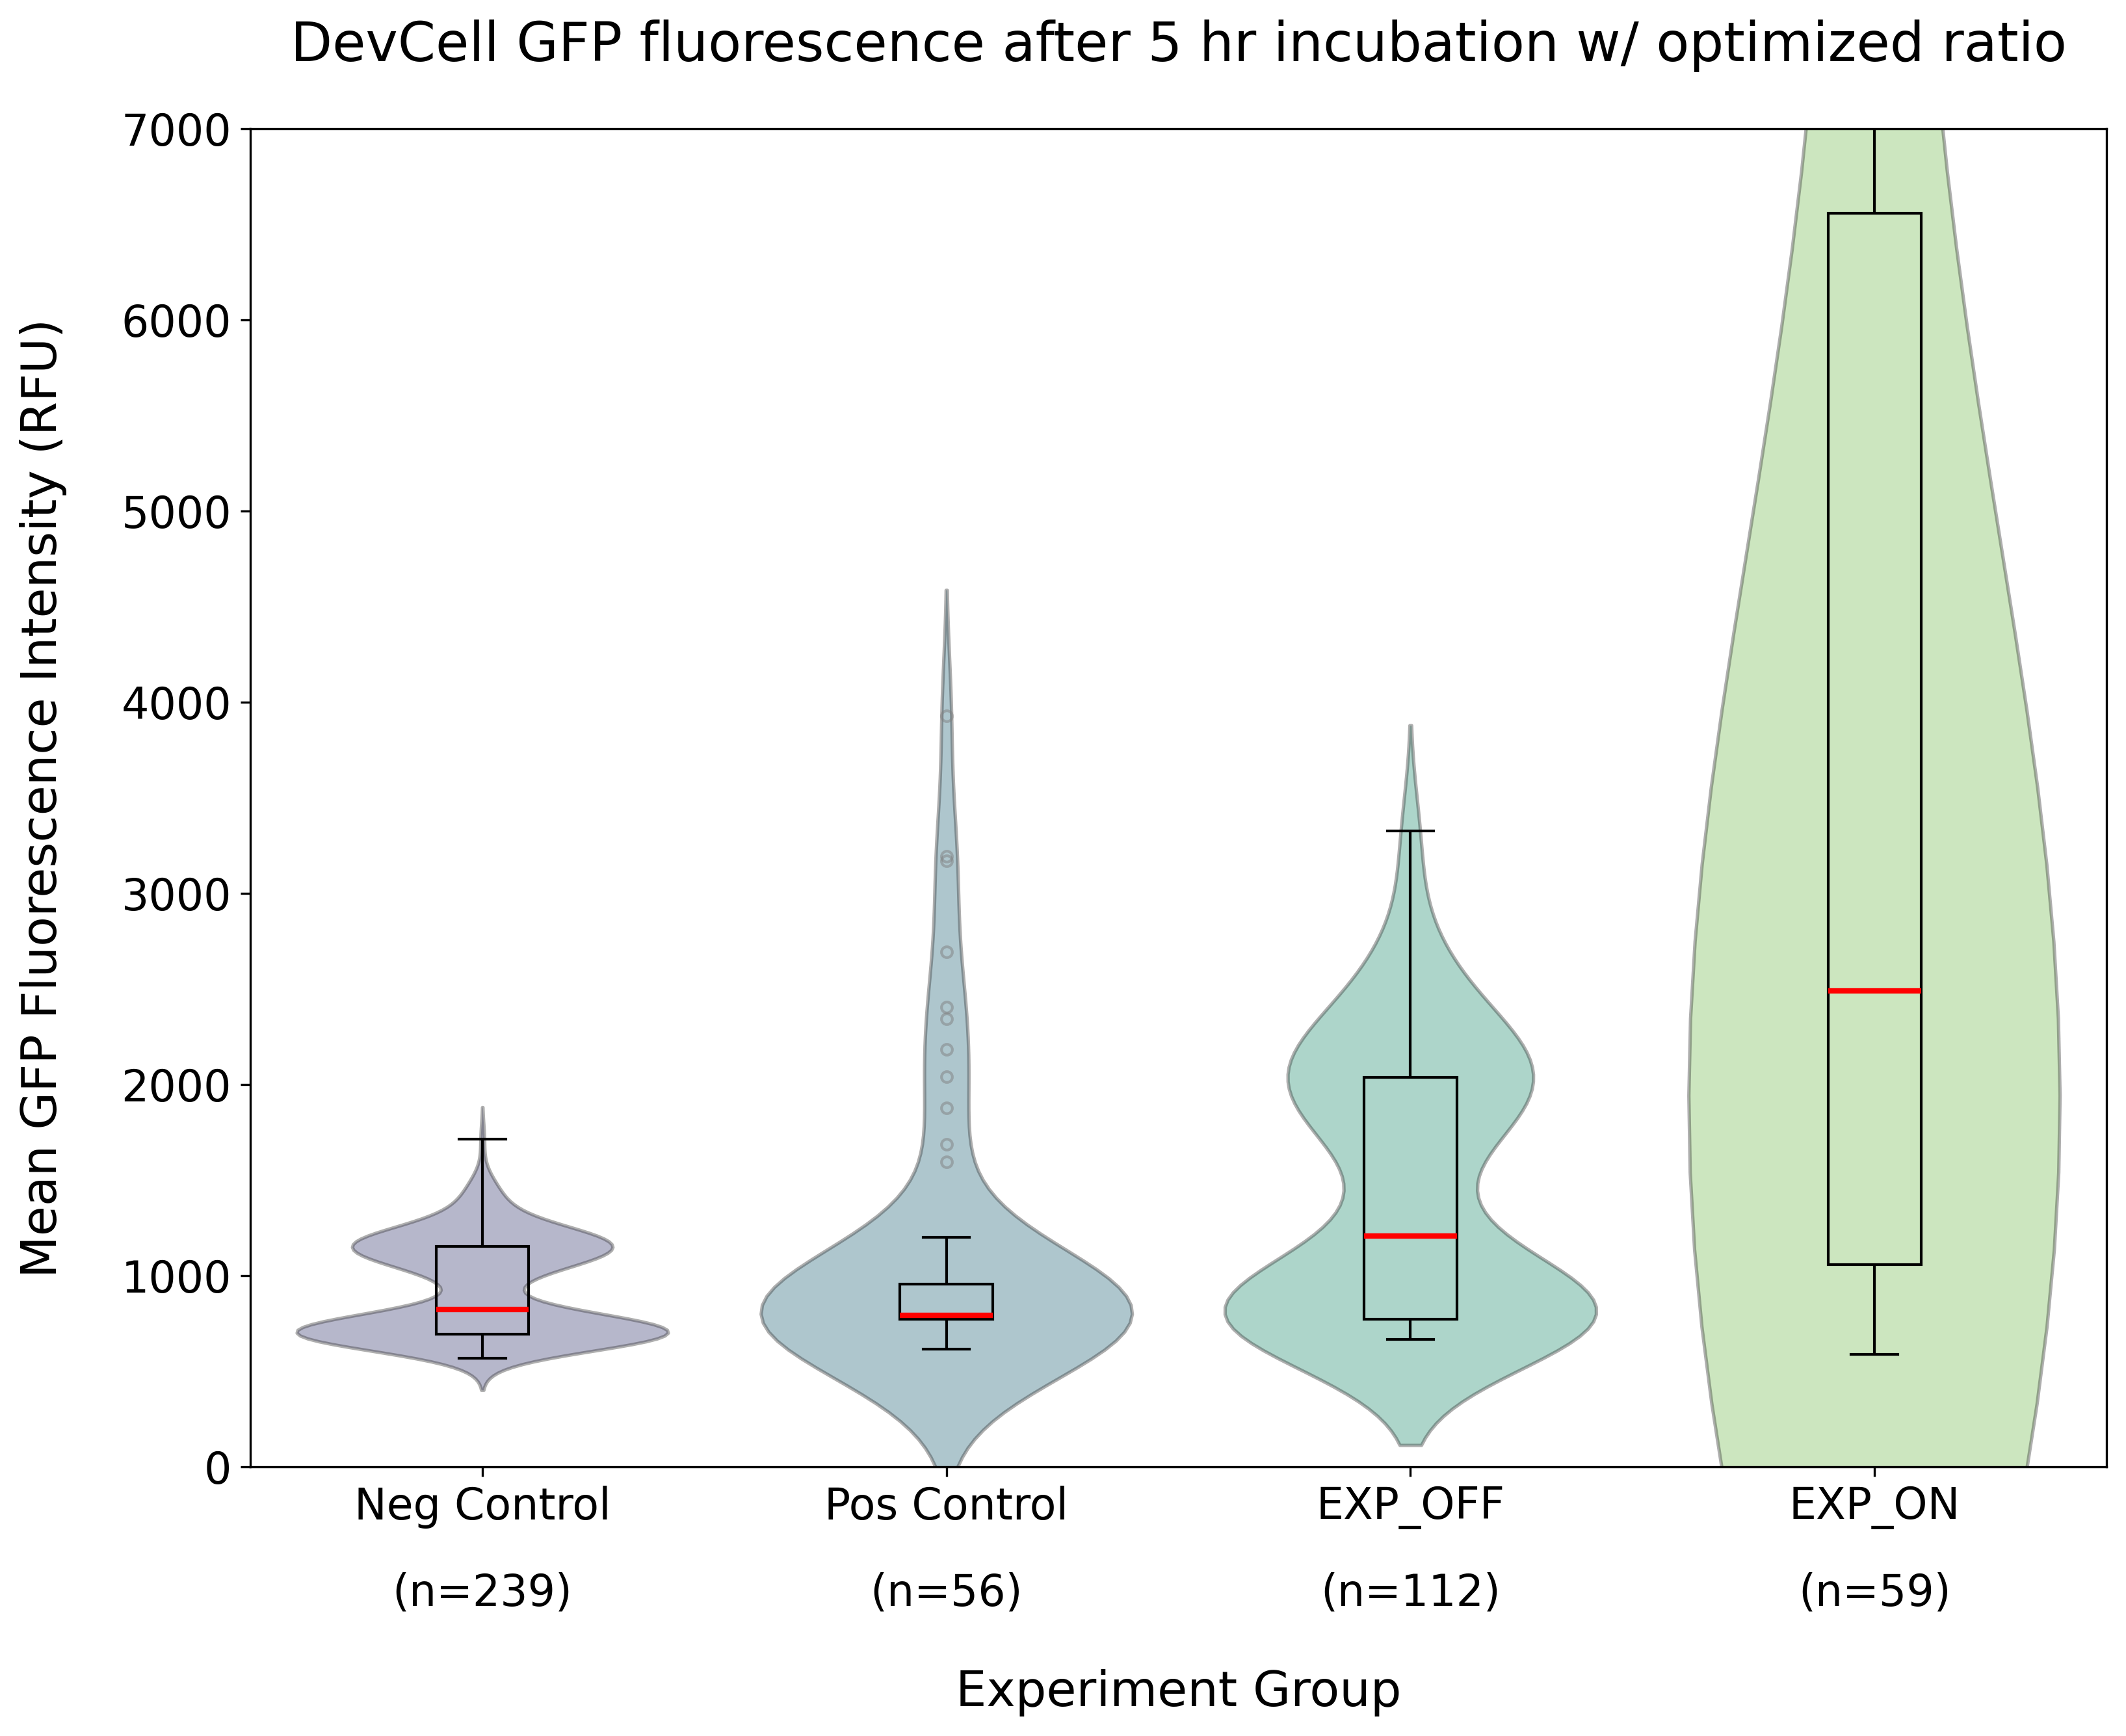

In [ ]:
#| label: fig8-quantified-gfp-5hr-all-conditions

fig, axes = plt.subplots(1, 1, figsize=(11, 9), dpi=300)

# Map the source groups to the new desired names
rename_dict = {'NEG': 'Neg Control', 'POS': 'Pos Control', 'EXP_OFF': 'EXP_OFF', 'EXP_ON': 'EXP_ON'}
GFP_expression_data['source_group_named'] = GFP_expression_data['source_group'].map(rename_dict)

# Define the desired order for the categories
well_order = ['Neg Control', 'Pos Control', 'EXP_OFF', 'EXP_ON']
GFP_expression_data['Well'] = pd.Categorical(GFP_expression_data['source_group_named'], categories=well_order, ordered=True)

# Calculate group counts for the x-axis labels
counts = GFP_expression_data['source_group_named'].value_counts()
# Add double newline characters for distinct vertical spacing
new_labels = [f"{group}\n\n(n={counts[group]})" for group in well_order]

# 1. Violin plot as the background
sns.violinplot(
    data=GFP_expression_data,
    x='source_group_named',
    order=well_order,
    y='Intensity Mean (GFP)',
    hue='source_group_named',
    ax=axes,
    palette='viridis',
    inner=None,
    alpha=0.4,
    legend=False
)

# 2. Box plot overlaid on top (made narrower with a distinct style)
sns.boxplot(
    data=GFP_expression_data,
    x='source_group_named',
    order=well_order,
    y='Intensity Mean (GFP)',
    ax=axes,
    width=0.2,
    boxprops={'facecolor': 'none', 'edgecolor': 'black', 'zorder': 2},
    whiskerprops={'color': 'black', 'zorder': 2},
    capprops={'color': 'black', 'zorder': 2},
    medianprops={'color': 'red', 'linewidth': 2, 'zorder': 3},
    showfliers=True,
    flierprops={'marker': 'o', 'markersize': 4, 'markeredgecolor': 'gray', 'alpha': 0.5}
)

# Style axes
axes.set_title('DevCell GFP fluorescence after 5 hr incubation w/ optimized ratio', fontsize=20, pad=25)
axes.set_xlabel('Experiment Group', fontsize=18, labelpad=20)
axes.set_ylabel('Mean GFP Fluorescence Intensity (RFU)', fontsize=18, labelpad=20)

# Apply the custom labels with larger fonts and explicit line spacing
axes.set_xticks(range(len(well_order)))
axes.set_xticklabels(new_labels, fontsize=16, linespacing=1)
axes.tick_params(axis='y', labelsize=16)
axes.set_ylim(0, 7000)

plt.tight_layout()

# Save the figure as a 300 DPI image
plt.savefig('devcell_gfp_fluorescence.png', dpi=300)
plt.show()